In [1]:
import random
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

CLASSES = ["Airplane", "Automobile", "Bird", "Cat", "Deer", "Dog", "Frog", "Horse", "Ship", "Truck"]

Device: cpu


In [2]:
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)

train_tf = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
test_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

train_data = datasets.CIFAR10("./data", train=True, download=True, transform=train_tf)
test_data = datasets.CIFAR10("./data", train=False, download=True, transform=test_tf)

train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=256)

C:\Users\Daryna\AppData\Local\Programs\Python\Python313\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


In [3]:
def block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )

model = nn.Sequential(
    block(3, 64),
    block(64, 128),
    block(128, 256),
    nn.Flatten(),
    nn.Dropout(0.3),
    nn.Linear(256 * 4 * 4, 10),   
).to(device)

print(model)
print("Параметров:", sum(p.numel() for p in model.parameters()))

Sequential(
  (0): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (1): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (2): Sequential(
    (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (3): Flatten(start_dim=1, end_dim=-1)
  (4): Dropout(p=0.3, inplace=False)
  (5): Linear

In [4]:
EPOCHS = 20
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=15, gamma=0.1)

def accuracy(loader):
    model.eval()
    correct = 0
    with torch.no_grad():
        for x, y in loader:
            correct += (model(x.to(device)).argmax(1).cpu() == y).sum().item()
    return correct / len(loader.dataset)

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x.size(0)
    scheduler.step()
    print(f"Epoch {epoch:02d}/{EPOCHS} | train loss={total_loss/len(train_data):.4f} | test acc={accuracy(test_loader):.4f}")

Epoch 01/20 | train loss=1.4982 | test acc=0.6228
Epoch 02/20 | train loss=1.0894 | test acc=0.6804
Epoch 03/20 | train loss=0.9517 | test acc=0.7077
Epoch 04/20 | train loss=0.8793 | test acc=0.7310
Epoch 05/20 | train loss=0.8103 | test acc=0.7737
Epoch 06/20 | train loss=0.7595 | test acc=0.7580
Epoch 07/20 | train loss=0.7119 | test acc=0.7743
Epoch 08/20 | train loss=0.6866 | test acc=0.7684
Epoch 09/20 | train loss=0.6588 | test acc=0.7928
Epoch 10/20 | train loss=0.6201 | test acc=0.7653
Epoch 11/20 | train loss=0.5977 | test acc=0.8046
Epoch 12/20 | train loss=0.5736 | test acc=0.7994
Epoch 13/20 | train loss=0.5554 | test acc=0.8222
Epoch 14/20 | train loss=0.5405 | test acc=0.8228
Epoch 15/20 | train loss=0.5195 | test acc=0.8257
Epoch 16/20 | train loss=0.4451 | test acc=0.8477
Epoch 17/20 | train loss=0.4287 | test acc=0.8462
Epoch 18/20 | train loss=0.4193 | test acc=0.8515
Epoch 19/20 | train loss=0.4153 | test acc=0.8513
Epoch 20/20 | train loss=0.4081 | test acc=0.8534


In [5]:
test_acc = accuracy(test_loader)
print(f"Test accuracy: {test_acc*100:.2f}%")
print("Бонус >80% выполнен ✅" if test_acc > 0.80 else "Бонус >80% не выполнен ❌")

Test accuracy: 85.34%
Бонус >80% выполнен ✅


In [6]:
model.eval()
probs, labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        probs.append(torch.softmax(model(x.to(device)), dim=1).cpu())
        labels.append(y)
probs, labels = torch.cat(probs), torch.cat(labels)
confs, preds = probs.max(dim=1)

def show(img):  
    mean, std = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)
    return (img * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

REAL: Ship | AI: Airplane ❌ | Confidence: 65%
REAL: Automobile | AI: Automobile ✅ | Confidence: 99%
REAL: Dog | AI: Dog ✅ | Confidence: 90%
REAL: Horse | AI: Horse ✅ | Confidence: 68%
REAL: Dog | AI: Dog ✅ | Confidence: 97%
REAL: Bird | AI: Bird ✅ | Confidence: 65%
REAL: Cat | AI: Cat ✅ | Confidence: 98%
REAL: Ship | AI: Ship ✅ | Confidence: 100%
REAL: Cat | AI: Dog ❌ | Confidence: 84%
REAL: Truck | AI: Automobile ❌ | Confidence: 91%
REAL: Bird | AI: Bird ✅ | Confidence: 96%
REAL: Dog | AI: Cat ❌ | Confidence: 60%
REAL: Deer | AI: Deer ✅ | Confidence: 71%
REAL: Automobile | AI: Automobile ✅ | Confidence: 55%
REAL: Airplane | AI: Airplane ✅ | Confidence: 65%
REAL: Dog | AI: Cat ❌ | Confidence: 84%
REAL: Truck | AI: Truck ✅ | Confidence: 98%
REAL: Cat | AI: Cat ✅ | Confidence: 98%
REAL: Dog | AI: Dog ✅ | Confidence: 84%
REAL: Airplane | AI: Airplane ✅ | Confidence: 85%


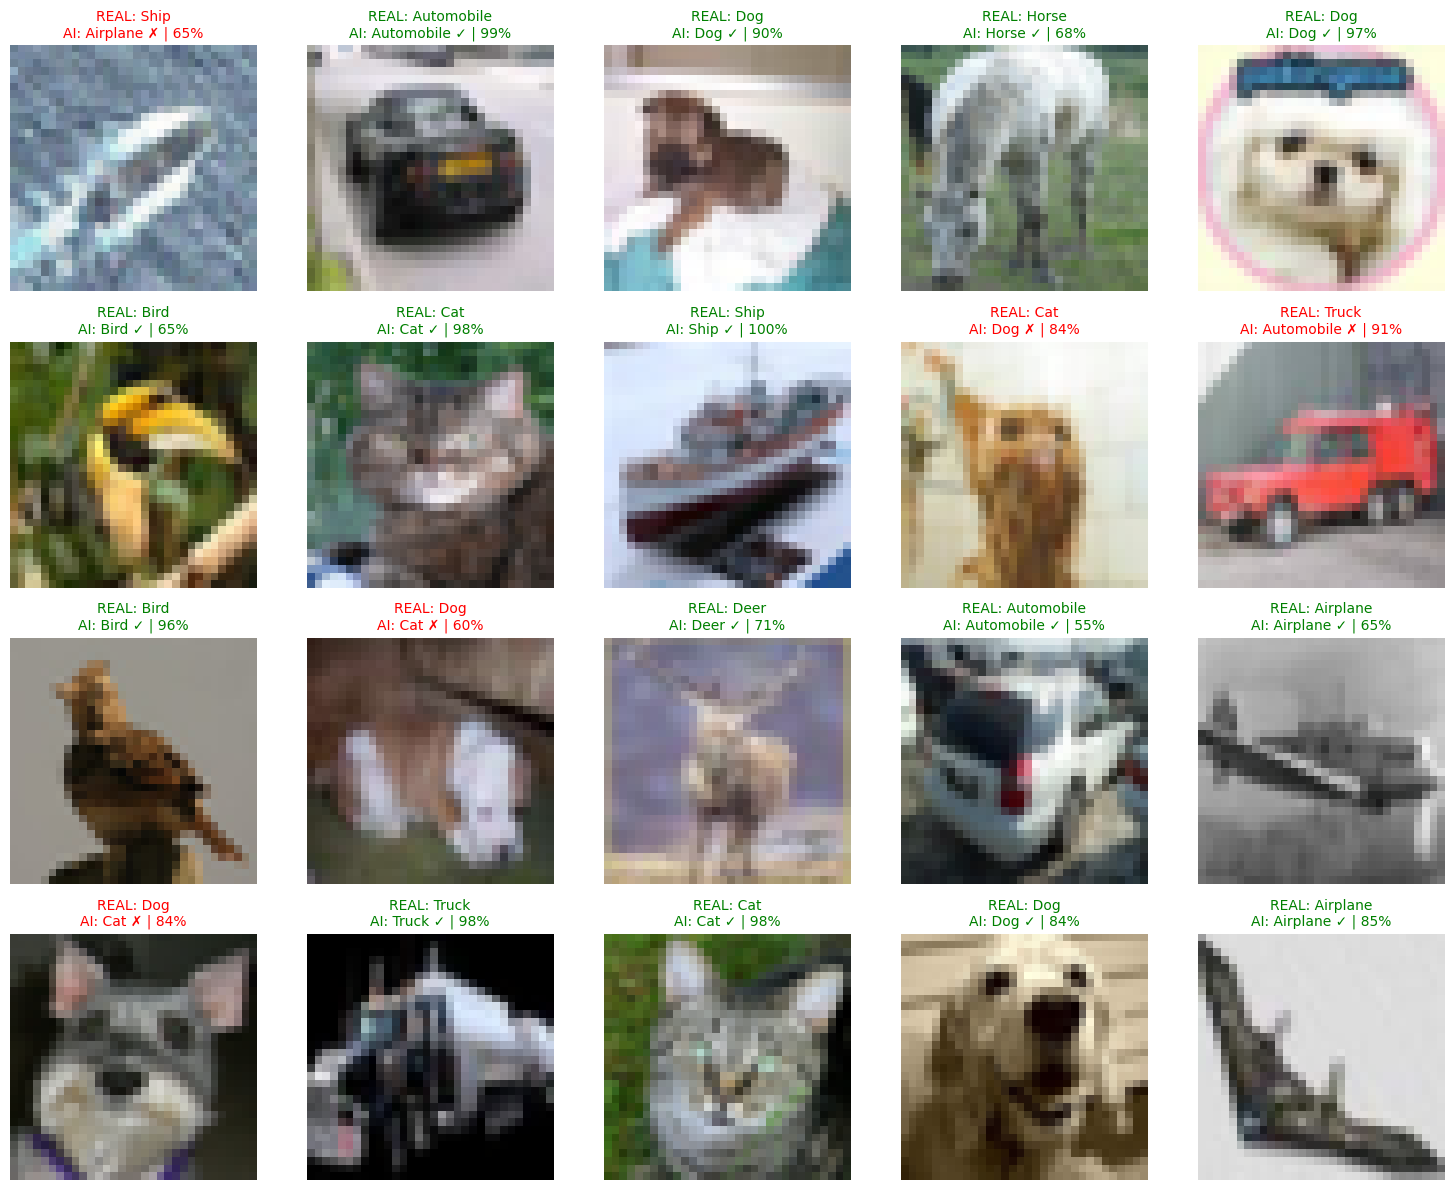

In [7]:
idxs = random.sample(range(len(test_data)), 20)
plt.figure(figsize=(15, 12))
for n, i in enumerate(idxs):
    real, pred, conf = CLASSES[labels[i]], CLASSES[preds[i]], confs[i].item() * 100
    ok = real == pred
    print(f"REAL: {real} | AI: {pred} {'✅' if ok else '❌'} | Confidence: {conf:.0f}%")
    plt.subplot(4, 5, n + 1)
    plt.imshow(show(test_data[i][0]))
    plt.title(f"REAL: {real}\nAI: {pred} {'✓' if ok else '✗'} | {conf:.0f}%", color="green" if ok else "red", fontsize=10)
    plt.axis("off")
plt.tight_layout()
plt.show()

REAL: Cat | AI: Frog ❌ | Confidence: 99.9%
REAL: Cat | AI: Deer ❌ | Confidence: 99.8%
REAL: Bird | AI: Frog ❌ | Confidence: 99.8%
REAL: Cat | AI: Frog ❌ | Confidence: 99.7%
REAL: Cat | AI: Dog ❌ | Confidence: 99.7%


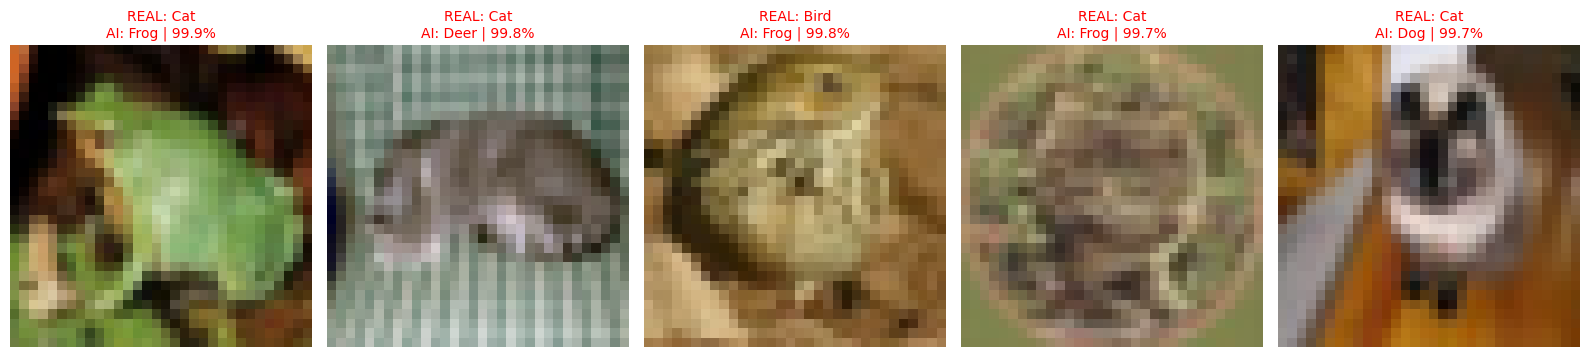

In [8]:
wrong = (preds != labels).nonzero(as_tuple=True)[0]
top5 = wrong[confs[wrong].argsort(descending=True)[:5]]

plt.figure(figsize=(16, 4))
for n, i in enumerate(top5):
    real, pred, conf = CLASSES[labels[i]], CLASSES[preds[i]], confs[i].item() * 100
    print(f"REAL: {real} | AI: {pred} ❌ | Confidence: {conf:.1f}%")
    plt.subplot(1, 5, n + 1)
    plt.imshow(show(test_data[i.item()][0]))
    plt.title(f"REAL: {real}\nAI: {pred} | {conf:.1f}%", color="red", fontsize=10)
    plt.axis("off")
plt.tight_layout()
plt.show()

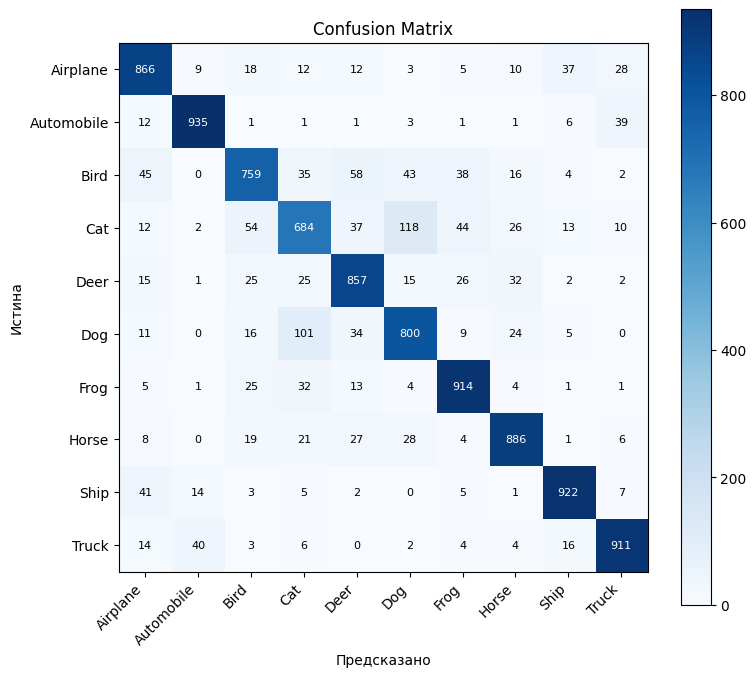

Топ-5 путаниц (истина → предсказание):
  Cat → Dog: 118
  Dog → Cat: 101
  Bird → Deer: 58
  Cat → Bird: 54
  Bird → Airplane: 45


In [9]:
cm = torch.zeros(10, 10, dtype=torch.long)
for t, p in zip(labels, preds):
    cm[t, p] += 1

plt.figure(figsize=(8, 7))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(10), CLASSES, rotation=45, ha="right")
plt.yticks(range(10), CLASSES)
plt.xlabel("Предсказано")
plt.ylabel("Истина")
plt.title("Confusion Matrix")
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j].item(), ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
plt.tight_layout()
plt.show()

pairs = [(cm[i, j].item(), CLASSES[i], CLASSES[j]) for i in range(10) for j in range(10) if i != j]
print("Топ-5 путаниц (истина → предсказание):")
for n, a, b in sorted(pairs, reverse=True)[:5]:
    print(f"  {a} → {b}: {n}")